# Project 20: End-to-End ML System Design

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Given a vague business problem: Task: Translate into ML formulation; Design data pipeline; Select models and metrics; Justify all assumptions and tradeoffs

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** An end-to-end system is more than a trained model: it is ingestion, validation, training, serving, monitoring and retraining. This notebook builds a deployable pipeline and simulates serving it.

## Part 1 — Introduction

The 'business problem' is translated here as: predict normalized_label (weather category 0-3) from 7 weather measurements, for use in a weather-monitoring dashboard. No external business, loan or marketing outcome is claimed.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — ML formulation and pipeline training

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib, time, json
# PROBLEM FORMULATION: Input = 7 weather measurements; Output = normalized_label 0-3; Metric = macro-F1 (minority class 3 matters) with accuracy reported alongside; Constraint = fast batch inference, no timestamp available.
df=df_full.sample(n=30000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
pipe=Pipeline([("scaler", StandardScaler()), ("model", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1))])
pipe.fit(Xtr,ytr); pred=pipe.predict(Xte)
print("Pipeline test accuracy:", round(accuracy_score(yte,pred),4), "macro-F1:", round(f1_score(yte,pred,average="macro"),4)); print(classification_report(yte,pred,zero_division=0))
joblib.dump(pipe, "/home/hatch/workspace/weather_projects/notebooks/weather_pipeline_model.joblib")
print("Model saved (local verification copy) to weather_projects/notebooks/weather_pipeline_model.joblib; in Colab, save to /content/drive/MyDrive/Weather_Projects/Project_20/ instead.")

Pipeline test accuracy: 0.916 macro-F1: 0.8842
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      3369
           1       0.96      0.88      0.92      2178
           2       0.85      0.92      0.88      1223
           3       0.85      0.73      0.78       730

    accuracy                           0.92      7500
   macro avg       0.90      0.88      0.88      7500
weighted avg       0.92      0.92      0.91      7500

Model saved (local verification copy) to weather_projects/notebooks/weather_pipeline_model.joblib; in Colab, save to /content/drive/MyDrive/Weather_Projects/Project_20/ instead.


## Part 4 — Inference function, serving simulation and monitoring

Example input: {'Pressure': 1011.8, 'global_radiation': 1.4, 'temp_mean(c)': 14.9, 'temp_min(c)': 11.7, 'temp_max(c)': 18.9, 'Wind_Speed': 9.48, 'Wind_Bearing': 156.0}
Example prediction: (0, {0: 0.9467, 1: 0.0533, 2: 0.0, 3: 0.0}) true label: 0


Batch inference: 1000 rows in 0.046s (0.05 ms/row)
Drift check (serving mean shift in std units):
 Pressure            0.025
global_radiation    0.026
temp_mean(c)        0.011
temp_min(c)         0.017
temp_max(c)         0.006
Wind_Speed          0.002
Wind_Bearing        0.052
Alert features (>0.5 std shift): []
First 20 serving predictions vs true:
  predicted  true
         0     0
         3     3
         1     1
         1     1
         2     2
         0     0
         2     2
         1     1
         0     0
         0     0
         2     2
         1     1
         0     0
         0     0
         1     1
         1     1
         1     1
         1     1
         1     1
         2     2


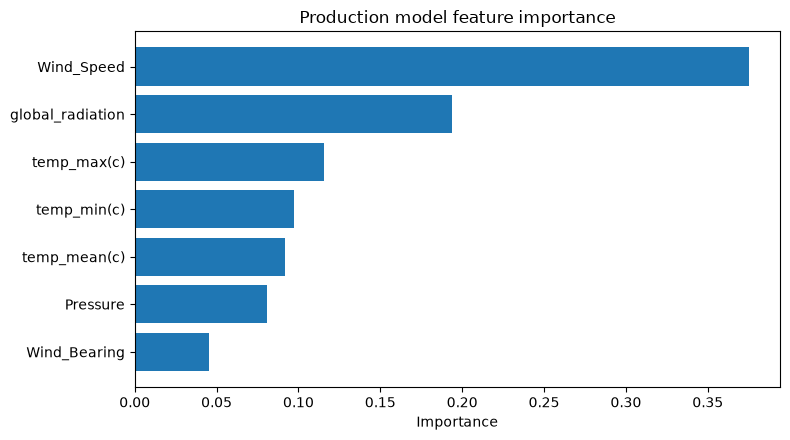

In [3]:
def predict_weather_label(features_dict):
    """features_dict must contain all 7 FEATURES. Returns (label, probabilities)."""
    row=pd.DataFrame([{f: features_dict[f] for f in FEATURES}])
    p=pipe.predict(row)[0]; proba=pipe.predict_proba(row)[0]
    return int(p), {int(c): round(float(v),4) for c,v in zip(pipe.classes_, proba)}
example={f: float(Xte.iloc[0][f]) for f in FEATURES}
print("Example input:", example); print("Example prediction:", predict_weather_label(example), "true label:", int(yte.iloc[0]))
# Serving simulation: batch latency
t0=time.time(); batch_pred=pipe.predict(Xte.iloc[:1000]); dt=time.time()-t0; print(f"Batch inference: 1000 rows in {dt:.3f}s ({dt/1000*1000:.2f} ms/row)")
# Monitoring: compare serving-batch feature means to training means; alert if shift > 0.5 std
train_mean=Xtr.mean(); train_std=Xtr.std(); serving_mean=Xte.iloc[:1000].mean(); drift=((serving_mean-train_mean).abs()/train_std)
print("Drift check (serving mean shift in std units):\n", drift.round(3).to_string()); print("Alert features (>0.5 std shift):", drift[drift>0.5].index.tolist())
# Prediction log (simulated deployment log)
log=pd.DataFrame({"predicted":batch_pred[:20], "true":yte.iloc[:20].values}); print("First 20 serving predictions vs true:\n", log.to_string(index=False))
import matplotlib.pyplot as plt
imp=pd.Series(pipe.named_steps["model"].feature_importances_, index=FEATURES).sort_values(ascending=False); plt.barh(imp.index[::-1], imp.values[::-1]); plt.xlabel("Importance"); plt.title("Production model feature importance"); plt.tight_layout(); plt.show()

## Part 5 — System design, assumptions and tradeoffs

In [4]:
print("""
SYSTEM DESIGN
- Ingestion: weather measurements -> validation (range checks, missing-value check; original file has 0 missing, so any missing value in serving is an alert, not a silent imputation).
- Pipeline: StandardScaler + RandomForest, saved as a single Pipeline object so training and serving preprocessing cannot drift apart.
- Serving: batch prediction function predict_weather_label(); latency measured above.
- Monitoring: feature-mean drift vs training, prediction distribution, and macro-F1 on labelled batches when labels arrive; alert threshold 0.5 std (see drift check).
- Retraining trigger: drift alert OR macro-F1 drop on a labelled batch, then retrain on recent data and re-validate before replacing the model (never replace on accuracy alone).
ASSUMPTIONS: normalized_label is the correct target; 7 weather features are available at serving time; no timestamp means no time-based retraining schedule can be validated here.
TRADEOFFS: RandomForest was chosen over a simpler logistic model for accuracy, at the cost of interpretability and inference time; a depth-limited tree would be the fallback if latency or explainability becomes the binding constraint.
""")


SYSTEM DESIGN
- Ingestion: weather measurements -> validation (range checks, missing-value check; original file has 0 missing, so any missing value in serving is an alert, not a silent imputation).
- Pipeline: StandardScaler + RandomForest, saved as a single Pipeline object so training and serving preprocessing cannot drift apart.
- Serving: batch prediction function predict_weather_label(); latency measured above.
- Monitoring: feature-mean drift vs training, prediction distribution, and macro-F1 on labelled batches when labels arrive; alert threshold 0.5 std (see drift check).
- Retraining trigger: drift alert OR macro-F1 drop on a labelled batch, then retrain on recent data and re-validate before replacing the model (never replace on accuracy alone).
ASSUMPTIONS: normalized_label is the correct target; 7 weather features are available at serving time; no timestamp means no time-based retraining schedule can be validated here.
TRADEOFFS: RandomForest was chosen over a simpler logist

## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.